# 01 - Explore the 100,023-row mock dataset

This notebook checks the exact mock row count and 22% fraud target, table schemas, label balance, and obvious synthetic-data artifacts.

In [1]:
from pathlib import Path
import subprocess
import sys

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))
DATA_DIR = PROJECT_ROOT / "data" / "mock_full"

if not (DATA_DIR / "transactions.csv").is_file():
    subprocess.run([
        sys.executable, str(PROJECT_ROOT / "scripts" / "mock_sandbox.py"),
        "--people", "4000", "--tx", "78018", "--cases", "8720", "--seed", "7",
        "--total-transactions", "100023", "--fraud-fraction", "0.22",
        "--out", str(DATA_DIR)
    ], check=True, cwd=PROJECT_ROOT)

from momo_fraud.io import load_tables
tables = load_tables(DATA_DIR, PROJECT_ROOT / "configs" / "columns.yaml")
transactions = tables["transactions"]
print(f"Rows: {len(transactions):,}")

Rows: 100,023


## Verify exact mock targets

In [2]:
print("Rows:", len(transactions))
print("Fraud rows:", int(transactions["is_fraud"].sum()))
print("Fraud fraction:", float(transactions["is_fraud"].mean()))
print("Fraud cases:", transactions["fraud_case"].nunique())
assert len(transactions) == 100023
assert 22004 <= int(transactions["is_fraud"].sum()) <= 22006

Rows: 100023
Fraud rows: 22005
Fraud fraction: 0.21999940013796826
Fraud cases: 8648


## Inspect tables and fraud kinds

In [3]:
import pandas as pd

summary = pd.DataFrame([
    {"table": name, "rows": len(frame), "columns": len(frame.columns)}
    for name, frame in tables.items()
])
display(summary)
display(transactions.groupby("fraud_scenario", dropna=False).agg(
    rows=("tx_id", "size"), total_amount=("amount", "sum")
).sort_values("rows", ascending=False))

,table,rows,columns
0,transactions,100023,11
1,blind_transactions,0,0
2,people,4012,3
3,sims,4513,6
4,wallets,4513,6
5,bank_accounts,1600,3
6,calls,43491,4
7,texts,102001,4
8,sim_events,6411,4
9,complaints,5235,4


,rows,total_amount
fraud_scenario,,
NaN,78018,13169524.92
limit_splitting,5976,28677289.24
mule_chain,4523,6598746.52
fake_merchant,3002,336084.42
agent_fraud,1747,2614966.09
pin_phishing,1701,1504954.98
sim_swap,1669,1500647.00
rtp_abuse,871,453144.86
fake_promo,869,139350.00


## Check amount and daily patterns

,tx_id,timestamp,type,payer_number,payee_number,amount,fee,is_fraud,fraud_scenario,fraud_role,fraud_case
0,TX0000000,2026-08-22 00:02:26+00:00,cash_in,0245078964,500811710,313.59,0.00,0,NaN,NaN,NaN
1,TX0000001,2026-08-22 00:02:40+00:00,cash_in,0249273246,241765131,338.76,0.00,0,NaN,NaN,NaN
2,TX0000002,2026-08-22 00:08:06+00:00,cash_in,0240825208,248596324,77.14,0.00,0,NaN,NaN,NaN
3,TX0000003,2026-08-22 00:10:43+00:00,p2p,0268694360,241337336,51.79,0.52,0,NaN,NaN,NaN
4,TX0000004,2026-08-22 00:12:12+00:00,p2p,0242107010,249539856,104.08,1.04,0,NaN,NaN,NaN


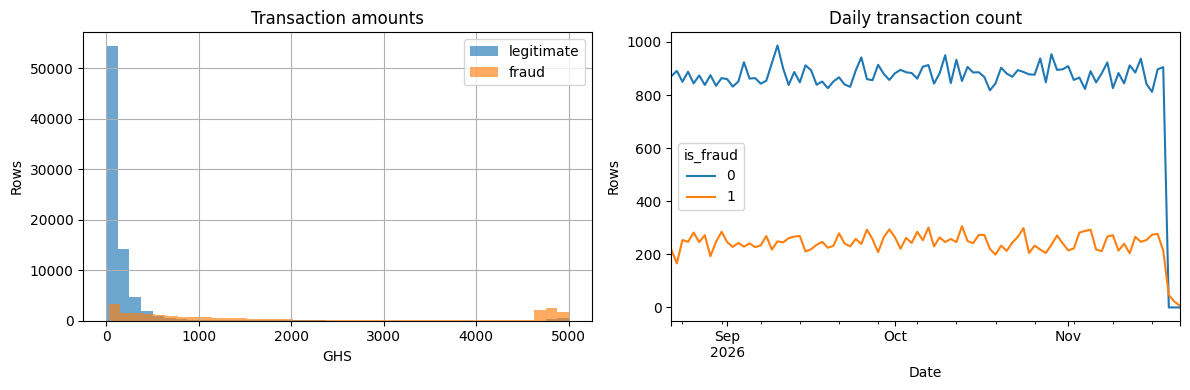

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
transactions.loc[transactions.is_fraud == 0, "amount"].clip(upper=5000).hist(bins=40, alpha=0.65, label="legitimate", ax=axes[0])
transactions.loc[transactions.is_fraud == 1, "amount"].clip(upper=5000).hist(bins=40, alpha=0.65, label="fraud", ax=axes[0])
axes[0].set(title="Transaction amounts", xlabel="GHS", ylabel="Rows")
axes[0].legend()
daily = transactions.assign(day=transactions.timestamp.dt.floor("D"))
daily.groupby(["day", "is_fraud"]).size().unstack(fill_value=0).plot(ax=axes[1])
axes[1].set(title="Daily transaction count", xlabel="Date", ylabel="Rows")
plt.tight_layout()
transactions.head()